In [10]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import TRAIN_A, TRAIN_B, RESULTS_DIR, MODELS_DIR

print("Project:", PROJECT_ROOT)
print("PyTorch:", torch.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")
print("Training directories exist:", TRAIN_A.exists(), TRAIN_B.exists())

Project: c:\TwinSepsis
PyTorch: 2.14.1+cpu
Device: cpu
Training directories exist: True True


In [11]:
import bisect
import json
import time
import joblib
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_ids = pd.read_csv(RESULTS_DIR / "train_patient_ids.csv")["patient_id"].astype(str).tolist()
val_ids = pd.read_csv(RESULTS_DIR / "val_patient_ids.csv")["patient_id"].astype(str).tolist()
test_ids = pd.read_csv(RESULTS_DIR / "test_patient_ids.csv")["patient_id"].astype(str).tolist()

all_patient_files = {}
for folder in (TRAIN_A, TRAIN_B):
    for path in folder.glob("*.psv"):
        all_patient_files[path.stem] = path

for name, ids in [("train", train_ids), ("validation", val_ids), ("test", test_ids)]:
    missing = [pid for pid in ids if pid not in all_patient_files]
    print(name, "patients:", len(ids), "| missing files:", len(missing))
    if missing:
        raise FileNotFoundError(f"{name}: missing patient files, e.g. {missing[:5]}")

print("Device:", DEVICE)

train patients: 28235 | missing files: 0
validation patients: 6050 | missing files: 0
test patients: 6051 | missing files: 0
Device: cpu


In [12]:
TARGET = "SepsisLabel"
DROP_COLUMNS = [TARGET, "patient_id"]

first_patient = pd.read_csv(all_patient_files[train_ids[0]], sep="|")
FEATURE_COLUMNS = [c for c in first_patient.columns if c not in DROP_COLUMNS]

print("Feature count:", len(FEATURE_COLUMNS))
print(FEATURE_COLUMNS)

def load_split(patient_ids, split_name):
    feature_parts = []
    label_parts = []
    patient_lengths = []

    for i, pid in enumerate(patient_ids, start=1):
        df = pd.read_csv(all_patient_files[pid], sep="|")

        # Keep feature order identical across every patient.
        x = df[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan)
        x = x.to_numpy(dtype=np.float32)

        y = df[TARGET].to_numpy(dtype=np.float32)

        feature_parts.append(x)
        label_parts.append(y)
        patient_lengths.append(len(df))

        if i % 5000 == 0:
            print(f"{split_name}: loaded {i:,}/{len(patient_ids):,} patients")

    X = np.concatenate(feature_parts, axis=0)
    y = np.concatenate(label_parts, axis=0)

    print(
        f"{split_name}: X={X.shape}, positives={int(y.sum()):,}, "
        f"positive rate={y.mean():.4%}"
    )
    return X, y, np.asarray(patient_lengths, dtype=np.int32)

X_train_raw, y_train, train_lengths = load_split(train_ids, "Train")
X_val_raw, y_val, val_lengths = load_split(val_ids, "Validation")
X_test_raw, y_test, test_lengths = load_split(test_ids, "Test")

Feature count: 40
['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS']


KeyboardInterrupt: 

In [ ]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train_raw).astype(np.float32)
X_val_imputed = imputer.transform(X_val_raw).astype(np.float32)
X_test_imputed = imputer.transform(X_test_raw).astype(np.float32)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train_imputed).astype(np.float32)
X_val = scaler.transform(X_val_imputed).astype(np.float32)
X_test = scaler.transform(X_test_imputed).astype(np.float32)

# Defensive handling of any unexpected non-finite results.
X_train = np.nan_to_num(X_train, nan=0.0, posinf=0.0, neginf=0.0)
X_val = np.nan_to_num(X_val, nan=0.0, posinf=0.0, neginf=0.0)
X_test = np.nan_to_num(X_test, nan=0.0, posinf=0.0, neginf=0.0)

assert X_train.shape[1] == len(FEATURE_COLUMNS)
assert X_train.shape[0] == len(y_train)
assert X_val.shape[0] == len(y_val)
assert X_test.shape[0] == len(y_test)

print("Preprocessing complete.")
print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)
print("All feature values finite:", np.isfinite(X_train).all()
      and np.isfinite(X_val).all() and np.isfinite(X_test).all())

Preprocessing complete.
Train: (1086436, 40) Validation: (231472, 40) Test: (234302, 40)
All feature values finite: True


In [ ]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(imputer, MODELS_DIR / "transformer_imputer.joblib")
joblib.dump(scaler, MODELS_DIR / "transformer_scaler.joblib")

with open(MODELS_DIR / "transformer_features.json", "w") as f:
    json.dump(FEATURE_COLUMNS, f, indent=2)
    

In [ ]:

SEQUENCE_LENGTH = 24

class PatientSequenceDataset(Dataset):
    def __init__(self, X, y, patient_lengths, sequence_length=24):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y.astype(np.float32))
        self.sequence_length = sequence_length

        self.starts = np.concatenate([
            np.array([0], dtype=np.int64),
            np.cumsum(patient_lengths[:-1], dtype=np.int64)
        ])

        self.lengths = patient_lengths.astype(np.int64)
        self.cumulative = np.cumsum(self.lengths)

        assert int(self.lengths.sum()) == len(self.y)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):
        patient_index = bisect.bisect_right(
            self.cumulative, index
        )

        patient_start = int(self.starts[patient_index])
        local_end = index - patient_start
        global_end = index + 1

        global_start = max(
            patient_start,
            global_end - self.sequence_length
        )

        seq = self.X[global_start:global_end]

        # True means this position is artificial padding.
        padding_mask = torch.zeros(
            self.sequence_length, dtype=torch.bool
        )

        pad_len = self.sequence_length - len(seq)

        if pad_len > 0:
            padding = torch.zeros(
                pad_len,
                self.X.shape[1],
                dtype=self.X.dtype,
            )
            seq = torch.cat([padding, seq], dim=0)
            padding_mask[:pad_len] = True

        assert seq.shape[0] == self.sequence_length
        assert padding_mask.shape[0] == self.sequence_length
        assert not padding_mask[-1].item()

        return seq, padding_mask, self.y[index]


train_dataset = PatientSequenceDataset(X_train, y_train, train_lengths, SEQUENCE_LENGTH)
val_dataset = PatientSequenceDataset(X_val, y_val, val_lengths, SEQUENCE_LENGTH)
test_dataset = PatientSequenceDataset(X_test, y_test, test_lengths, SEQUENCE_LENGTH)

print("Sequence length:", SEQUENCE_LENGTH)
print("Training windows:", len(train_dataset))
print("Validation windows:", len(val_dataset))
print("Test windows:", len(test_dataset))


sample_x, sample_mask, sample_y = train_dataset[100]

print("One sequence shape:", sample_x.shape)
print("One padding mask shape:", sample_mask.shape)
print("Padded positions:", sample_mask.sum().item())
print("One label:", sample_y.item())


Sequence length: 24
Training windows: 1086436
Validation windows: 231472
Test windows: 234302
One sequence shape: torch.Size([24, 40])
One padding mask shape: torch.Size([24])
Padded positions: 10
One label: 0.0


In [14]:

class SepsisTransformer(nn.Module):
    def __init__(
        self,
        input_features,
        sequence_length=24,
        d_model=64,
        num_heads=4,
        num_layers=2,
        dropout=0.1,
    ):
        super().__init__()

        self.input_projection = nn.Linear(input_features, d_model)
        self.position_embedding = nn.Embedding(sequence_length, d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=128,
            dropout=dropout,
            batch_first=True,
            norm_first=False,
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
        )

        self.norm = nn.LayerNorm(d_model)
        self.output_layer = nn.Linear(d_model, 1)

    def forward(self, x, padding_mask=None):
        seq_len = x.shape[1]
        positions = torch.arange(seq_len, device=x.device)

        x = self.input_projection(x)
        x = x + self.position_embedding(positions).unsqueeze(0)

        x = self.encoder(
            x,
            src_key_padding_mask=padding_mask,
        )

        x = self.norm(x[:, -1, :])
        return self.output_layer(x).squeeze(-1)


# Create a fresh model using the corrected class.
model = SepsisTransformer(
    input_features=len(FEATURE_COLUMNS),
    sequence_length=SEQUENCE_LENGTH,
).to(DEVICE)

print("Model created:", type(model).__name__)
print("Forward method:", inspect.signature(model.forward))


Model created: SepsisTransformer
Forward method: (x, padding_mask=None)


In [15]:
BATCH_SIZE = 64
EPOCHS = 5
LEARNING_RATE = 1e-3
PATIENCE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

positive_count = float(y_train.sum())
negative_count = float(len(y_train) - positive_count)
positive_weight = negative_count / max(positive_count, 1)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor([positive_weight], dtype=torch.float32, device=DEVICE)
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4,
)

print("Positive class weight:", round(positive_weight, 2))
print("Batches per epoch:", len(train_loader))

Positive class weight: 54.54
Batches per epoch: 16976


In [18]:

def collect_predictions(model, loader):
    model.eval()
    all_probs = []
    all_labels = []

    with torch.no_grad():
        for xb, padding_mask, yb in loader:
            xb = xb.to(DEVICE)
            padding_mask = padding_mask.to(DEVICE)

            logits = model(xb, padding_mask=padding_mask)
            probs = torch.sigmoid(logits)

            all_probs.append(probs.cpu().numpy())
            all_labels.append(yb.numpy())

    return np.concatenate(all_labels), np.concatenate(all_probs)


def calculate_metrics(y_true, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)

    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "f1": f1_score(y_true, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "auprc": average_precision_score(y_true, probabilities),
        "confusion_matrix": confusion_matrix(
            y_true, predictions
        ).tolist(),
    }


In [19]:
best_val_auc = -np.inf
epochs_without_improvement = 0
history = []

best_model_path = MODELS_DIR / "transformer_best.pt"
history_path = RESULTS_DIR / "transformer_training_history.csv"

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()
    model.train()
    total_loss = 0.0
    samples_seen = 0

    for batch_idx, (xb, padding_mask, yb) in enumerate(train_loader, start=1):
        xb = xb.to(DEVICE)
        padding_mask = padding_mask.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        logits = model(xb, padding_mask=padding_mask)
        loss = criterion(logits, yb)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )
        optimizer.step()

        total_loss += loss.item() * len(yb)
        samples_seen += len(yb)

        if batch_idx % 500 == 0:
            print(
                f"Epoch {epoch}/{EPOCHS} | "
                f"Batch {batch_idx}/{len(train_loader)} | "
                f"Loss {loss.item():.4f}"
            )

    train_loss = total_loss / samples_seen

    y_val_true, val_probs = collect_predictions(model, val_loader)
    val_metrics = calculate_metrics(y_val_true, val_probs)

    elapsed = time.time() - start_time

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_roc_auc": val_metrics["roc_auc"],
        "val_auprc": val_metrics["auprc"],
        "val_precision_at_0_5": val_metrics["precision"],
        "val_recall_at_0_5": val_metrics["recall"],
        "seconds": elapsed,
    }
    history.append(record)
    pd.DataFrame(history).to_csv(history_path, index=False)

    print(
        f"\nEpoch {epoch}: train_loss={train_loss:.4f}, "
        f"val_AUROC={val_metrics['roc_auc']:.4f}, "
        f"val_AUPRC={val_metrics['auprc']:.4f}, "
        f"time={elapsed/60:.1f} min\n"
    )

    if val_metrics["roc_auc"] > best_val_auc:
        best_val_auc = val_metrics["roc_auc"]
        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "feature_columns": FEATURE_COLUMNS,
                "sequence_length": SEQUENCE_LENGTH,
                "d_model": 64,
                "num_heads": 4,
                "num_layers": 2,
                "epoch": epoch,
                "val_roc_auc": best_val_auc,
            },
            best_model_path,
        )
        print("Saved best checkpoint:", best_model_path)
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping: validation AUROC did not improve.")
        break

print("Training finished.")

Epoch 1/5 | Batch 500/16976 | Loss 2.3921
Epoch 1/5 | Batch 1000/16976 | Loss 0.1039
Epoch 1/5 | Batch 1500/16976 | Loss 1.1907
Epoch 1/5 | Batch 2000/16976 | Loss 6.3350
Epoch 1/5 | Batch 2500/16976 | Loss 0.4838
Epoch 1/5 | Batch 3000/16976 | Loss 1.8666
Epoch 1/5 | Batch 3500/16976 | Loss 0.2141
Epoch 1/5 | Batch 4000/16976 | Loss 0.3001
Epoch 1/5 | Batch 4500/16976 | Loss 2.0174
Epoch 1/5 | Batch 5000/16976 | Loss 2.3089
Epoch 1/5 | Batch 5500/16976 | Loss 1.9156
Epoch 1/5 | Batch 6000/16976 | Loss 3.8614
Epoch 1/5 | Batch 6500/16976 | Loss 0.3055
Epoch 1/5 | Batch 7000/16976 | Loss 1.8837
Epoch 1/5 | Batch 7500/16976 | Loss 0.2806
Epoch 1/5 | Batch 8000/16976 | Loss 0.4707
Epoch 1/5 | Batch 8500/16976 | Loss 2.4152
Epoch 1/5 | Batch 9000/16976 | Loss 0.1637
Epoch 1/5 | Batch 9500/16976 | Loss 0.2226
Epoch 1/5 | Batch 10000/16976 | Loss 1.4520
Epoch 1/5 | Batch 10500/16976 | Loss 1.9799
Epoch 1/5 | Batch 11000/16976 | Loss 1.7554
Epoch 1/5 | Batch 11500/16976 | Loss 1.6511
Epoch 1/

c:\TwinSepsis\.venv\Lib\site-packages\torch\nn\modules\transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\NestedTensorImpl.cpp:181.)
  output = torch._nested_tensor_from_mask(



Epoch 1: train_loss=1.4161, val_AUROC=0.7283, val_AUPRC=0.0668, time=18.1 min

Saved best checkpoint: C:\TwinSepsis\models\transformer_best.pt
Epoch 2/5 | Batch 500/16976 | Loss 0.1708
Epoch 2/5 | Batch 1000/16976 | Loss 0.1972
Epoch 2/5 | Batch 1500/16976 | Loss 2.2998
Epoch 2/5 | Batch 2000/16976 | Loss 0.5339
Epoch 2/5 | Batch 2500/16976 | Loss 0.3180
Epoch 2/5 | Batch 3000/16976 | Loss 0.2188
Epoch 2/5 | Batch 3500/16976 | Loss 1.0583
Epoch 2/5 | Batch 4000/16976 | Loss 0.2621
Epoch 2/5 | Batch 4500/16976 | Loss 2.0185
Epoch 2/5 | Batch 5000/16976 | Loss 0.2590
Epoch 2/5 | Batch 5500/16976 | Loss 1.9446
Epoch 2/5 | Batch 6000/16976 | Loss 2.0154
Epoch 2/5 | Batch 6500/16976 | Loss 3.6471
Epoch 2/5 | Batch 7000/16976 | Loss 0.2819
Epoch 2/5 | Batch 7500/16976 | Loss 2.9339
Epoch 2/5 | Batch 8000/16976 | Loss 1.9523
Epoch 2/5 | Batch 8500/16976 | Loss 4.5919
Epoch 2/5 | Batch 9000/16976 | Loss 0.2500
Epoch 2/5 | Batch 9500/16976 | Loss 1.3902
Epoch 2/5 | Batch 10000/16976 | Loss 0.3

In [20]:
checkpoint = torch.load(
    best_model_path,
    map_location=DEVICE,
    weights_only=False,
)

model.load_state_dict(checkpoint["model_state_dict"])

y_test_true, test_probs = collect_predictions(model, test_loader)

test_metrics = calculate_metrics(y_test_true, test_probs, threshold=0.5)

print("Best epoch:", checkpoint["epoch"])
print("Best validation AUROC:", checkpoint["val_roc_auc"])
print("\nTEST METRICS")
for key, value in test_metrics.items():
    print(f"{key}: {value}")

Best epoch: 1
Best validation AUROC: 0.7282751576843272

TEST METRICS
threshold: 0.5
accuracy: 0.9304658090840027
precision: 0.10541422048271364
recall: 0.38531235097758704
f1: 0.165539848391723
roc_auc: 0.7580285179311501
auprc: 0.08106829738751307
confusion_matrix: [[216394, 13714], [2578, 1616]]


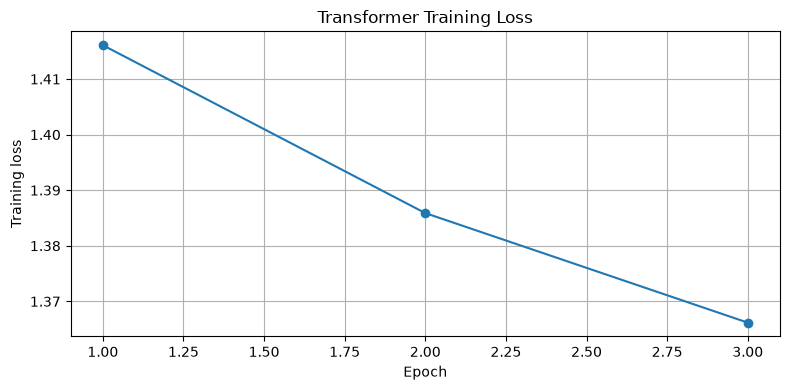

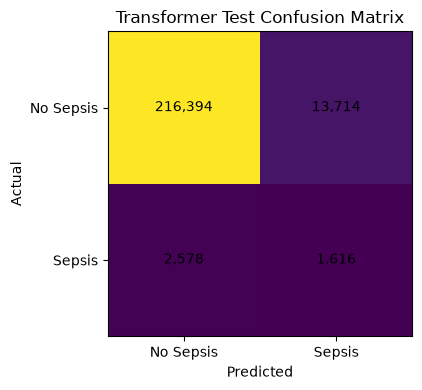

In [23]:
history_df = pd.read_csv(history_path)

plt.figure(figsize=(8, 4))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Transformer Training Loss")
plt.grid(True)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "transformer_training_loss.png", dpi=150)
plt.show()

cm = np.array(test_metrics["confusion_matrix"])

plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Transformer Test Confusion Matrix")
plt.xticks([0, 1], ["No Sepsis", "Sepsis"])
plt.yticks([0, 1], ["No Sepsis", "Sepsis"])
plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(2):
    for j in range(2):
        plt.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "transformer_test_confusion_matrix.png", dpi=150)
plt.show()

In [24]:

# Save corrected Transformer results separately.
# Requires test_metrics, checkpoint, and cm from the evaluation cell.

metrics_to_save = {
    key: value
    for key, value in test_metrics.items()
    if key != "confusion_matrix"
}

metrics_to_save.update({
    "model": "Transformer_padding_mask",
    "best_epoch": checkpoint["epoch"],
    "best_validation_roc_auc": checkpoint["val_roc_auc"],
    "sequence_length": SEQUENCE_LENGTH,
    "batch_size": BATCH_SIZE,
})

pd.DataFrame([metrics_to_save]).to_csv(
    RESULTS_DIR / "transformer_test_metrics_padding_mask.csv",
    index=False,
)

pd.DataFrame(
    cm,
    index=["Actual_No_Sepsis", "Actual_Sepsis"],
    columns=["Predicted_No_Sepsis", "Predicted_Sepsis"],
).to_csv(
    RESULTS_DIR / "transformer_test_confusion_matrix_padding_mask.csv"
)

print("Corrected Transformer results saved separately.")


Corrected Transformer results saved separately.
